## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 


Part1: Understanding product categories

In [5]:
import pandas as pd

df = pd.read_csv("dataset/amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [9]:
frequency_table = df["category"].value_counts().reset_index()
frequency_table.columns = ["Category", "Frequency"]
display(frequency_table)

,Category,Frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Alexa Built-In Devices,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [11]:
top_5 = df["category"].value_counts().head(5)
display(top_5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

<Axes: title={'center': 'Top 20 Product Categories'}, xlabel='Product Category', ylabel='Number of Products'>

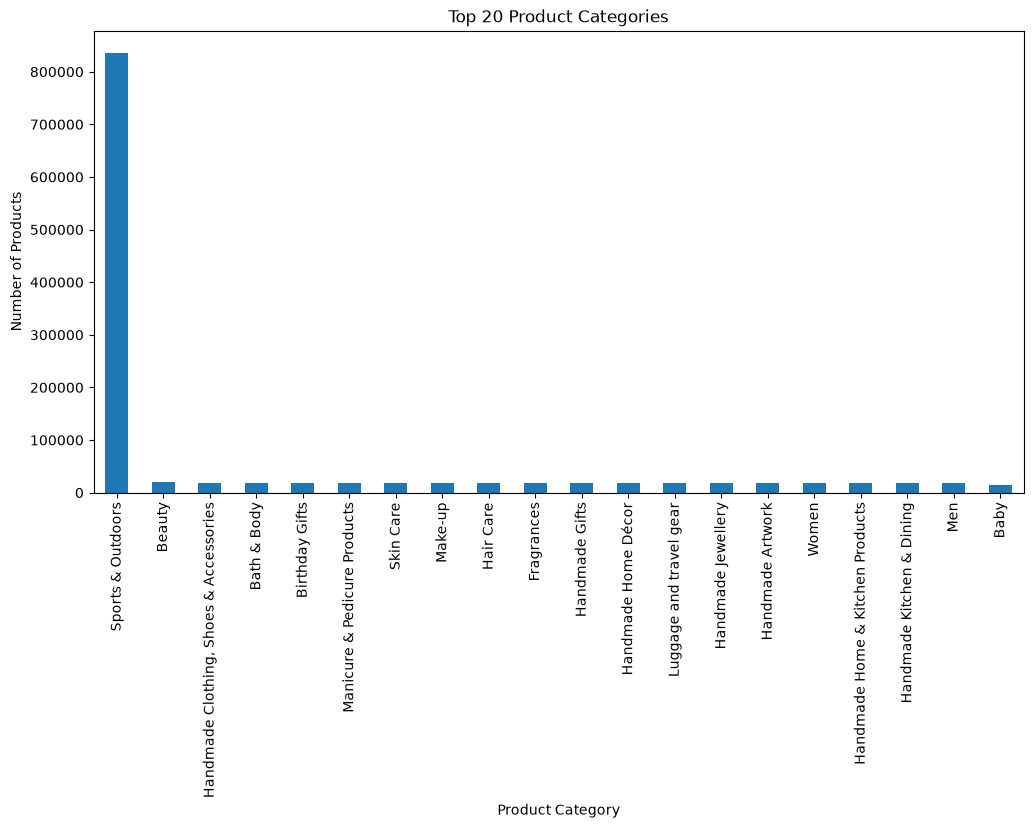

In [15]:
df["category"].value_counts().head(20).plot.bar(
    title="Top 20 Product Categories",
    xlabel="Product Category",
    ylabel="Number of Products",
    figsize=(12, 6)
)

<Axes: title={'center': 'Top 5 Product Categories'}>

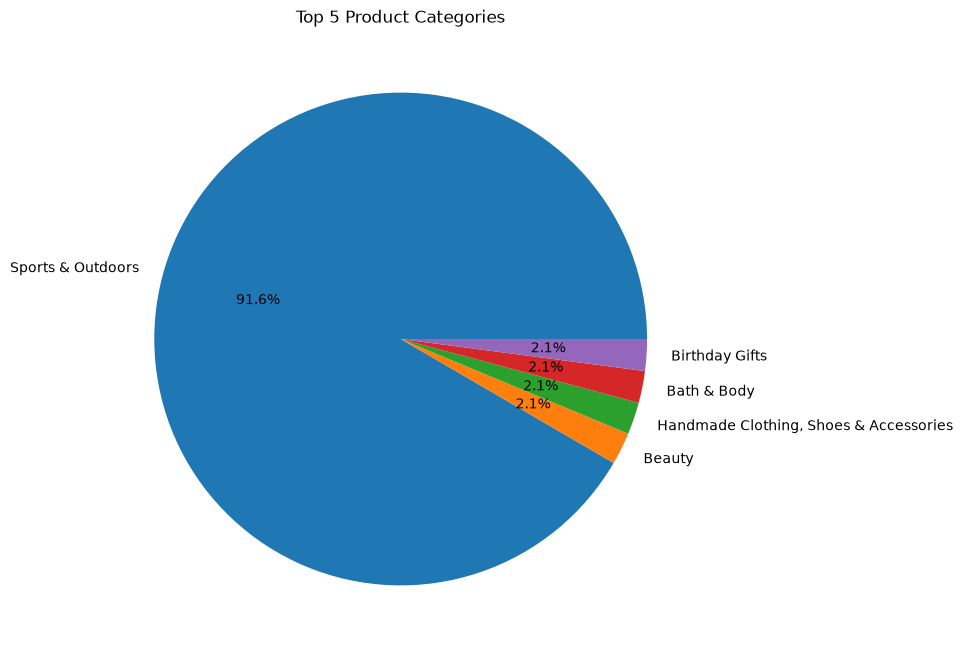

In [25]:
top_5.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    title='Top 5 Product Categories',
    ylabel=""
)

Question 1: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

The 5 category of products that are more listed in Amazon UK are in order: 1) Sports & Outdoors with 836.265 products, 2)Beauty with 19.312 products, 3) Handmade Clothing, Shoes & Accessories with 19.229 products, 4)Bath & Body with 19.092 products and finally 5)Birthday Gifts with 18.978 products

in terms of listing frequency, Sports and Outdoors is the clear dominant Category. As seen in the bar chart above, Sports and Outdoors greatly outnumbers the following 19 most popular categories by a grand margin and when compared propoertionally with the top 5 Categories (see pie chart), it encompases 91.6% of the total products.



### Part 2: Delving into Product Pricing

**Measures of Centrality**:

In [26]:
mean = df["price"].mean()
median = df["price"].median()
mode = df["price"].mode()

print("The average price of all products is: ", mean)
print("The median price of all products is: ", median)
print("The most common price of all products is: ", mode)

The average price of all products is:  89.24380943923661
The median price of all products is:  19.09
The most common price of all products is:  0    9.99
Name: price, dtype: float64


the average price is significantly higher than the median, meaning that there is a small number of costly products that are elevating the average of prices. This possibly indicates a statistical skew in pricing data.

**Measures of Dispersion**:

In [33]:
variance = df["price"].var()
standard_deviation = df["price"].std()
range = df["price"].max() - df["price"].min()
interquartile_range = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print("The variance of prices is: ", variance.round(2))
print("The Standard deviation of prices is: ", standard_deviation.round(2))
print("The difference between the maximum and minimum prices is: ", range)
print("The interquartile range is: ", interquartile_range)

The variance of prices is:  119445.49
The Standard deviation of prices is:  345.61
The difference between the maximum and minimum prices is:  100000.0
The interquartile range is:  36.0


In [31]:
price = df["price"]
price_stats = pd.DataFrame({
    "Variance": [price.var()],
    "Standard Deviation": [price.std()],
    "Range": [price.max() - price.min()],
    "IQR": [price.quantile(0.75) - price.quantile(0.25)]
})

display(price_stats.round(2))

,Variance,Standard Deviation,Range,IQR
0,119445.49,345.61,100000.0,36.0


The product prices show a substantial spread, with prices having a maximum difference of 100.000 pounds. However, the majority of the products in the middle range are priced closed according to the interquartile range. The standard deviation of 345.61 pounds indicates considerable variation around the average price.

<Axes: title={'center': 'Distribution of prices'}, xlabel='Price in GBP', ylabel='Frequency'>

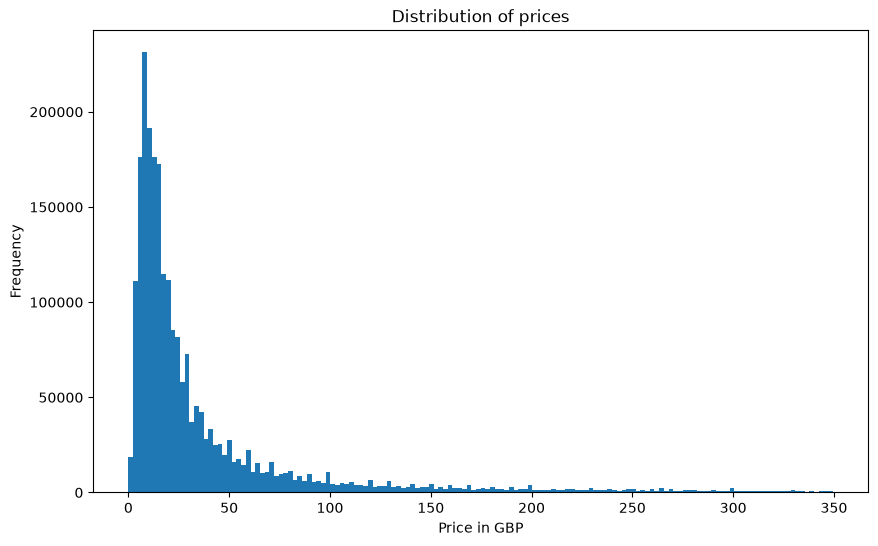

In [38]:
df[df["price"] <= df["price"].quantile(0.95)]["price"].plot.hist(
    bins=150,
    figsize=(10, 6),
    title='Distribution of prices',
    xlabel='Price in GBP',
    ylabel='Frequency'
)

<Axes: >

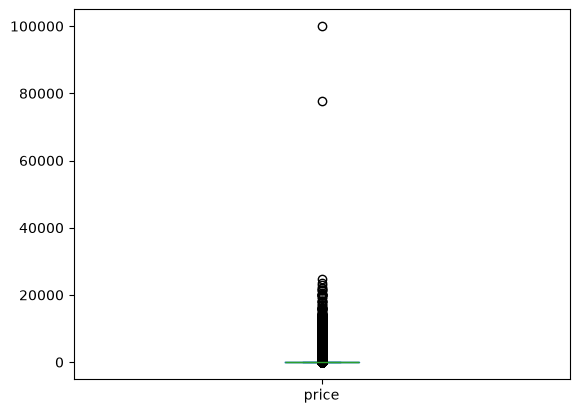

In [39]:
df["price"].plot.box()

there are 2 products that are significantly more expensive than the rest

Business Question 2: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

The prices of Amazon UK vary considerably. Although most products are concentrated in the low range (below 50 pounds) and the interquantile range indicates that the middle 50% of the products are within a 36 GBP range. However, there is a large standard deviation of 345.61 GBP and extremely large range of 100,000 GBP which is due to the 2 products that are outliers as seen on the plot box chart above. 

### Part 3: Unpacking Product Ratings

In [ ]:
#Checking for ratings of 0 or null in stars column
print("Zero values:", (df["stars"] == 0).sum())
print("Null values:", df["stars"].isna().sum())

Zero values: 1225641
Null values: 0


In [47]:
#excluding the zero values from the analysis
rating = df["stars"].replace(0, pd.NA).dropna()

In [49]:
#Calculating the Measures of centrality

mean = rating.mean()
median = rating.median()
mode = rating.mode().tolist()

print("The mean of the ratings is:", mean.round(2))
print("The median of the ratings is:", median)
print("The mode of the ratings is:", mode)

The mean of the ratings is: 4.32
The median of the ratings is: 4.4
The mode of the ratings is: [4.5]


 How do customers generally rate products? Is there a common trend?

It seems most of the costumers leave no reviews when purchasing products from Amazon UK. However, those who leave a review give high ratings, with an average rating of 4.32. Both the median and mode of raings are positioned closely to the average, at 4.4 and 4.5 respectively 

**Measures of Dispersion**:

In [50]:
variance = rating.var()
std_dev = rating.std()
iqr = rating.quantile(0.75) - rating.quantile(0.25)

print("Variance:", round(variance, 2))
print("Standard Deviation:", round(std_dev, 2))
print("Interquartile Range:", round(iqr, 2))

Variance: 0.31
Standard Deviation: 0.56
Interquartile Range: 0.5


The ratings from customers seem to be consistent as it has imited variation. The standard deviation of 0.56 indicates that ratings are grouped around the mean, while the interquartile range of 0.5 shows that the middle 50% of ratings fall within a half-star interval.

**Shape of the Distribution**:

In [52]:
skewness = round(rating.skew(), 2)
kurtosis = round(rating.kurt(),2)

print("Skew of the ratings is: ", skewness)
print("Kurtosis of the ratings is: ", kurtosis)

Skew of the ratings is:  -2.38
Kurtosis of the ratings is:  9.78


Most Amazon UK products appear to receive relatively high and consistent customer ratings. However, a smaller number of products receive substantially lower ratings, producing strong negative skewness and high kurtosis. Therefore, the distribution not normal, despite the low standard deviation.

**Visualizations**

<Axes: title={'center': 'Distribution of Amazon Product Ratings'}, xlabel='Rating (Stars)', ylabel='Frequency'>

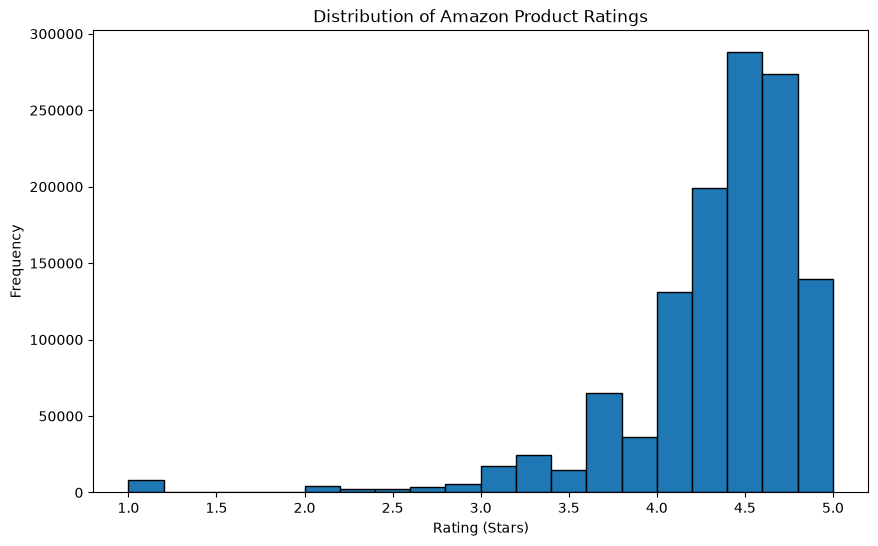

In [53]:
rating.plot.hist(bins=20, figsize=(10, 6), title="Distribution of Amazon Product Ratings", xlabel="Rating (Stars)", ylabel="Frequency", edgecolor="black")

The rating of 4.5 is the most repeated. Most products recieve ratings between 4 and 4.8 stars

**Business Question 3**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

The products of Amazon UK recieve high and consistent ratings. Most products recieve between 4 and 4.8 stars with most of the products recieving 4.5 stars.
This is also shown when analyzing the standard deviation (0.56) and interquartile range(0.5) which indicates limited variation in ratings. However, because most customers who actually leave reviews, give high rating, the distribution is not normal, with a very strong right skewness (-2.38) and kurtosis (9.78)